In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

DATA_PATH = Path("../data/raw/recipes.csv")

In [3]:
print("Fichier :", DATA_PATH)
print("Existe :", DATA_PATH.exists())

if DATA_PATH.exists():
    print(f"Taille : {DATA_PATH.stat().st_size / (1024**2):.2f} MB")

Fichier : ..\data\raw\recipes.csv
Existe : True
Taille : 671.59 MB


In [4]:
recipes_sample = pd.read_csv(DATA_PATH, nrows=5)

print("Nombre de colonnes :", len(recipes_sample.columns))
print("\nColonnes :")
for i, col in enumerate(recipes_sample.columns, 1):
    print(f"{i}. {col}")

Nombre de colonnes : 28

Colonnes :
1. RecipeId
2. Name
3. AuthorId
4. AuthorName
5. CookTime
6. PrepTime
7. TotalTime
8. DatePublished
9. Description
10. Images
11. RecipeCategory
12. Keywords
13. RecipeIngredientQuantities
14. RecipeIngredientParts
15. AggregatedRating
16. ReviewCount
17. Calories
18. FatContent
19. SaturatedFatContent
20. CholesterolContent
21. SodiumContent
22. CarbohydrateContent
23. FiberContent
24. SugarContent
25. ProteinContent
26. RecipeServings
27. RecipeYield
28. RecipeInstructions


In [5]:
recipes_sample.head()

,RecipeId,Name,AuthorId,AuthorName,CookTime,PrepTime,TotalTime,DatePublished,Description,Images,RecipeCategory,Keywords,RecipeIngredientQuantities,RecipeIngredientParts,AggregatedRating,ReviewCount,Calories,FatContent,SaturatedFatContent,CholesterolContent,SodiumContent,CarbohydrateContent,FiberContent,SugarContent,ProteinContent,RecipeServings,RecipeYield,RecipeInstructions
0,38,Low-Fat Berry Blue Frozen Dessert,1533,Dancer,PT24H,PT45M,PT24H45M,1999-08-09T21:46:00Z,Make and share this Low-Fat Berry Blue Frozen Dessert recipe from Food.com.,"c(""https://img.sndimg.com/food/image/upload/w_555,h_416,c_fit,fl_progressive,q_95/v1/img/recipes...",Frozen Desserts,"c(""Dessert"", ""Low Protein"", ""Low Cholesterol"", ""Healthy"", ""Free Of..."", ""Summer"", ""Weeknight"", ""...","c(""4"", ""1/4"", ""1"", ""1"")","c(""blueberries"", ""granulated sugar"", ""vanilla yogurt"", ""lemon juice"")",4.5,4,170.9,2.5,1.3,8.0,29.8,37.1,3.6,30.2,3.2,4,NaN,"c(""Toss 2 cups berries with sugar."", ""Let stand for 45 minutes, stirring occasionally."", ""Transf..."
1,39,Biryani,1567,elly9812,PT25M,PT4H,PT4H25M,1999-08-29T13:12:00Z,Make and share this Biryani recipe from Food.com.,"c(""https://img.sndimg.com/food/image/upload/w_555,h_416,c_fit,fl_progressive,q_95/v1/img/recipes...",Chicken Breast,"c(""Chicken Thigh & Leg"", ""Chicken"", ""Poultry"", ""Meat"", ""Asian"", ""Indian"", ""Weeknight"", ""Stove Top"")","c(""1"", ""4"", ""2"", ""2"", ""8"", ""1/4"", ""8"", ""1/2"", ""1"", ""1"", ""1/4"", ""1/4"", ""1/2"", ""1/4"", ""2"", ""3"", NA...","c(""saffron"", ""milk"", ""hot green chili peppers"", ""onions"", ""garlic"", ""clove"", ""peppercorns"", ""car...",3.0,1,1110.7,58.8,16.6,372.8,368.4,84.4,9.0,20.4,63.4,6,NaN,"c(""Soak saffron in warm milk for 5 minutes and puree in blender."", ""Add chiles, onions, ginger, ..."
2,40,Best Lemonade,1566,Stephen Little,PT5M,PT30M,PT35M,1999-09-05T19:52:00Z,This is from one of my first Good House Keeping cookbooks. You must use a *zester* in order to...,"c(""https://img.sndimg.com/food/image/upload/w_555,h_416,c_fit,fl_progressive,q_95/v1/img/recipes...",Beverages,"c(""Low Protein"", ""Low Cholesterol"", ""Healthy"", ""Summer"", ""< 60 Mins"")","c(""1 1/2"", ""1"", NA, ""1 1/2"", NA, ""3/4"")","c(""sugar"", ""lemons, rind of"", ""lemon, zest of"", ""fresh water"", ""fresh lemon juice"")",4.5,10,311.1,0.2,0.0,0.0,1.8,81.5,0.4,77.2,0.3,4,NaN,"c(""Into a 1 quart Jar with tight fitting lid, put sugar and lemon peel, or zest; add 1 1/2 cups..."
3,41,Carina's Tofu-Vegetable Kebabs,1586,Cyclopz,PT20M,PT24H,PT24H20M,1999-09-03T14:54:00Z,This dish is best prepared a day in advance to allow the ingredients to soak in the marinade ov...,"c(""https://img.sndimg.com/food/image/upload/w_555,h_416,c_fit,fl_progressive,q_95/v1/img/recipes...",Soy/Tofu,"c(""Beans"", ""Vegetable"", ""Low Cholesterol"", ""Weeknight"", ""Broil/Grill"", ""Oven"")","c(""12"", ""1"", ""2"", ""1"", ""10"", ""1"", ""3"", ""2"", ""2"", ""2"", ""1"", ""2"", ""1/2"", ""1/4"", ""4"")","c(""extra firm tofu"", ""eggplant"", ""zucchini"", ""mushrooms"", ""soy sauce"", ""low sodium soy sauce"", ""...",4.5,2,536.1,24.0,3.8,0.0,1558.6,64.2,17.3,32.1,29.3,2,4 kebabs,"c(""Drain the tofu, carefully squeezing out excess water, and pat dry with paper towels."", ""Cut ..."
4,42,Cabbage Soup,1538,Duckie067,PT30M,PT20M,PT50M,1999-09-19T06:19:00Z,Make and share this Cabbage Soup recipe from Food.com.,"""https://img.sndimg.com/food/image/upload/w_555,h_416,c_fit,fl_progressive,q_95/v1/img/recipes/4...",Vegetable,"c(""Low Protein"", ""Vegan"", ""Low Cholesterol"", ""Healthy"", ""Winter"", ""< 60 Mins"", ""Easy"")","c(""46"", ""4"", ""1"", ""2"", ""1"")","c(""plain tomato juice"", ""cabbage"", ""onion"", ""carrots"", ""celery"")",4.5,11,103.6,0.4,0.1,0.0,959.3,25.1,4.8,17.7,4.3,4,NaN,"c(""Mix everything together and bring to a boil."", ""Reduce heat and simmer for 30 minutes (longer..."


In [6]:
recipes_sample.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5 entries, 0 to 4
Data columns (total 28 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   RecipeId                    5 non-null      int64  
 1   Name                        5 non-null      object 
 2   AuthorId                    5 non-null      int64  
 3   AuthorName                  5 non-null      object 
 4   CookTime                    5 non-null      object 
 5   PrepTime                    5 non-null      object 
 6   TotalTime                   5 non-null      object 
 7   DatePublished               5 non-null      object 
 8   Description                 5 non-null      object 
 9   Images                      5 non-null      object 
 10  RecipeCategory              5 non-null      object 
 11  Keywords                    5 non-null      object 
 12  RecipeIngredientQuantities  5 non-null      object 
 13  RecipeIngredientParts       5 non-null 

In [7]:
recipes_sample.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
RecipeId,5.0,NaN,NaN,NaN,40.0,1.581139,38.0,39.0,40.0,41.0,42.0
Name,5,5,Low-Fat Berry Blue Frozen Dessert,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
AuthorId,5.0,NaN,NaN,NaN,1558.0,22.102036,1533.0,1538.0,1566.0,1567.0,1586.0
AuthorName,5,5,Dancer,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
CookTime,5,5,PT24H,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
PrepTime,5,5,PT45M,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TotalTime,5,5,PT24H45M,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
DatePublished,5,5,1999-08-09T21:46:00Z,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,5,5,Make and share this Low-Fat Berry Blue Frozen Dessert recipe from Food.com.,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Images,5,5,"c(""https://img.sndimg.com/food/image/upload/w_555,h_416,c_fit,fl_progressive,q_95/v1/img/recipes...",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
total_rows = 0

for chunk in pd.read_csv(DATA_PATH, chunksize=50_000):
    total_rows += len(chunk)

print("Nombre total de recettes :", total_rows)
print("Nombre total de colonnes :", len(recipes_sample.columns))

Nombre total de recettes : 522517
Nombre total de colonnes : 28


In [9]:
recipes_sample.dtypes

RecipeId                        int64
Name                           object
AuthorId                        int64
AuthorName                     object
CookTime                       object
PrepTime                       object
TotalTime                      object
DatePublished                  object
Description                    object
Images                         object
RecipeCategory                 object
Keywords                       object
RecipeIngredientQuantities     object
RecipeIngredientParts          object
AggregatedRating              float64
ReviewCount                     int64
Calories                      float64
FatContent                    float64
SaturatedFatContent           float64
CholesterolContent            float64
SodiumContent                 float64
CarbohydrateContent           float64
FiberContent                  float64
SugarContent                  float64
ProteinContent                float64
RecipeServings                  int64
RecipeYield 

In [10]:
missing_counts = pd.Series(0, index=recipes_sample.columns, dtype="int64")

for chunk in pd.read_csv(DATA_PATH, chunksize=50_000):
    missing_counts += chunk.isna().sum()

missing_df = pd.DataFrame({
    "missing_count": missing_counts,
    "missing_percentage": (missing_counts / total_rows) * 100
})

missing_df = missing_df.sort_values(
    "missing_percentage",
    ascending=False
)

missing_df

,missing_count,missing_percentage
RecipeYield,348071,66.614292
AggregatedRating,253223,48.462155
ReviewCount,247489,47.364775
RecipeServings,182911,35.005751
CookTime,82545,15.797572
Keywords,17237,3.298840
RecipeCategory,751,0.143727
Description,5,0.000957
RecipeIngredientQuantities,3,0.000574
Images,1,0.000191


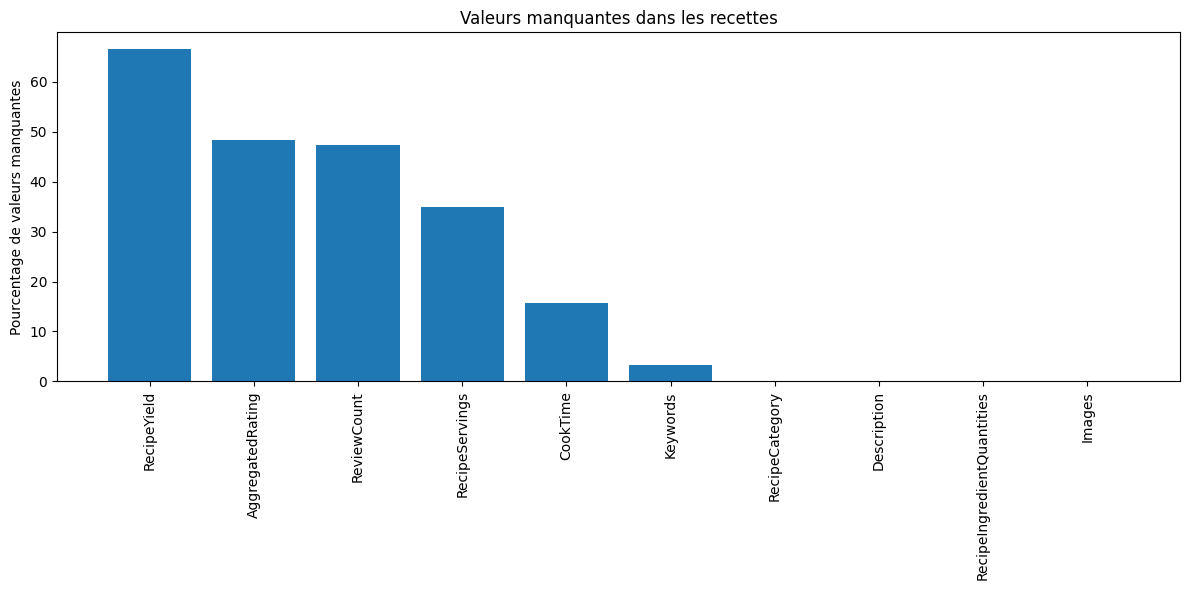

In [11]:
missing_plot = missing_df[missing_df["missing_count"] > 0]

plt.figure(figsize=(12, 6))

plt.bar(
    missing_plot.index,
    missing_plot["missing_percentage"]
)

plt.xticks(rotation=90)
plt.ylabel("Pourcentage de valeurs manquantes")
plt.title("Valeurs manquantes dans les recettes")
plt.tight_layout()
plt.show()

In [12]:
unique_counts = pd.Series(0, index=recipes_sample.columns, dtype="int64")

for chunk in pd.read_csv(DATA_PATH, chunksize=50_000):
    for col in chunk.columns:
        unique_counts[col] += chunk[col].nunique(dropna=True)

unique_counts.sort_values(ascending=False)

RecipeId                      522517
RecipeInstructions            520903
Description                   512352
RecipeIngredientParts         510754
RecipeIngredientQuantities    493954
Name                          493832
Keywords                      277689
DatePublished                 245548
SodiumContent                 175947
Images                        165899
Calories                      132349
AuthorId                       87166
AuthorName                     86979
RecipeYield                    57697
CholesterolContent             48327
CarbohydrateContent            34161
SugarContent                   24447
FatContent                     22171
ProteinContent                 14213
SaturatedFatContent            12477
FiberContent                    5839
TotalTime                       5735
RecipeCategory                  2679
CookTime                        2307
PrepTime                        1516
ReviewCount                     1361
RecipeServings                   943
A

In [13]:
numeric_columns = recipes_sample.select_dtypes(
    include=np.number
).columns.tolist()

print("Colonnes numériques :")
for col in numeric_columns:
    print("-", col)

Colonnes numériques :
- RecipeId
- AuthorId
- AggregatedRating
- ReviewCount
- Calories
- FatContent
- SaturatedFatContent
- CholesterolContent
- SodiumContent
- CarbohydrateContent
- FiberContent
- SugarContent
- ProteinContent
- RecipeServings


In [16]:
numeric_columns = recipes_sample.select_dtypes(include=np.number).columns.tolist()

outlier_results = []

for col in numeric_columns:
    values = []

    for chunk in pd.read_csv(
        DATA_PATH,
        usecols=[col],
        chunksize=50000
    ):
        values.extend(pd.to_numeric(chunk[col], errors="coerce").dropna().tolist())

    values = np.array(values, dtype=np.float64)

    Q1 = np.percentile(values, 25)
    Q3 = np.percentile(values, 75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((values < lower) | (values > upper)).sum()

    outlier_results.append({
        "column": col,
        "Q1": Q1,
        "Q3": Q3,
        "lower_bound": lower,
        "upper_bound": upper,
        "outlier_count": outliers,
        "outlier_percentage": outliers / len(values) * 100
    })

outliers_df = pd.DataFrame(outlier_results)

outliers_df.sort_values(
    "outlier_percentage",
    ascending=False
)

,column,Q1,Q3,lower_bound,upper_bound,outlier_count,outlier_percentage
3,ReviewCount,1.0,4.0,-3.50,8.50,31398,11.416292
13,RecipeServings,4.0,8.0,-2.00,14.00,36947,10.879372
11,SugarContent,2.5,17.9,-20.60,41.00,53424,10.224356
1,AuthorId,69474.0,565828.0,-675057.00,1310359.00,46381,8.876458
10,FiberContent,0.8,4.6,-4.90,10.30,38419,7.352679
5,FatContent,5.6,27.4,-27.10,60.10,37655,7.206464
8,SodiumContent,123.3,792.2,-880.05,1795.55,37587,7.193450
6,SaturatedFatContent,1.5,10.8,-12.45,24.75,37040,7.088765
4,Calories,174.2,529.1,-358.15,1061.45,35905,6.871547
9,CarbohydrateContent,12.8,51.1,-44.65,108.55,35360,6.767244


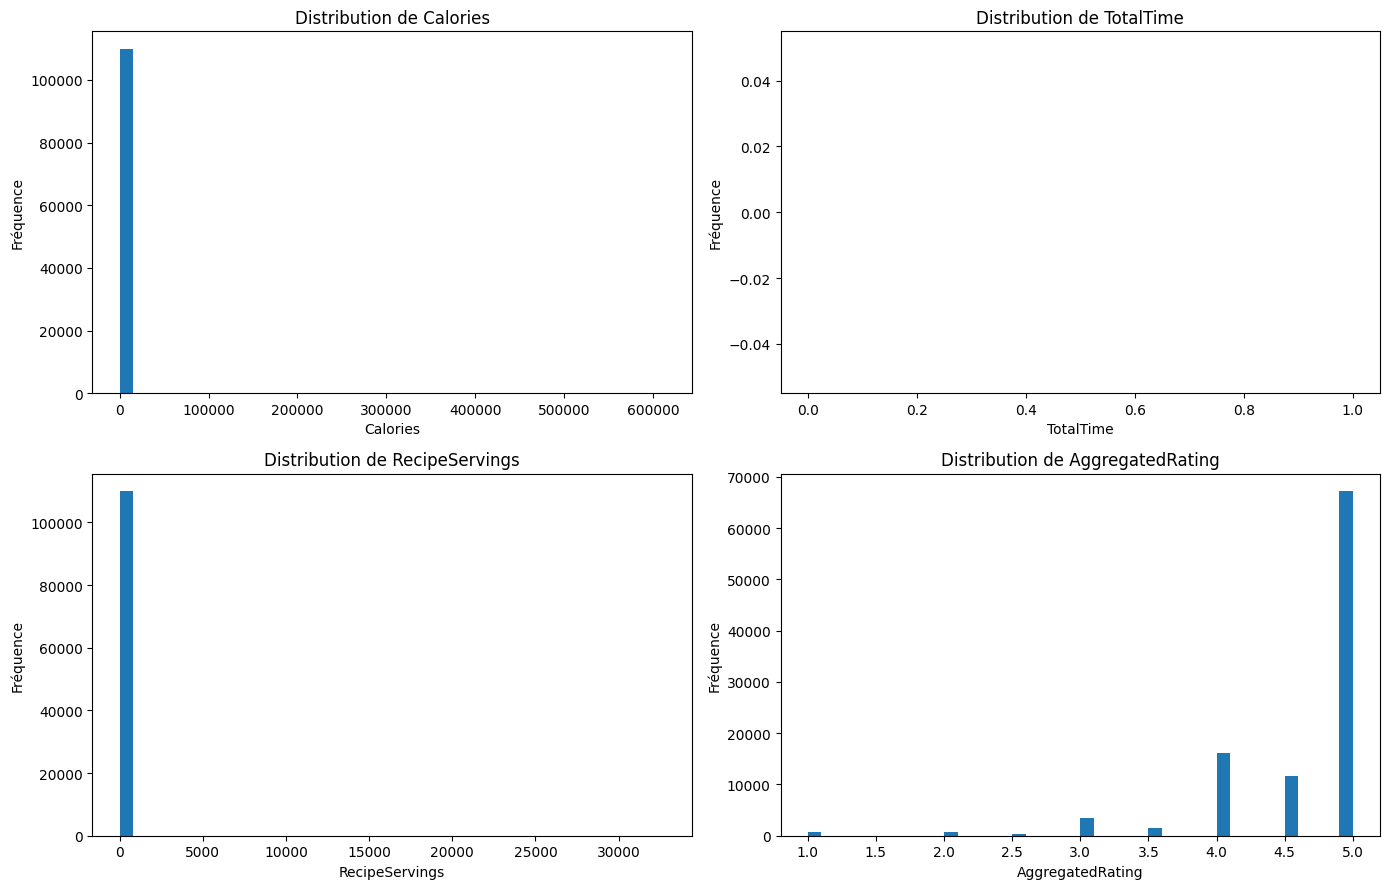

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

columns = [
    "Calories",
    "TotalTime",
    "RecipeServings",
    "AggregatedRating"
]

for ax, col in zip(axes.ravel(), columns):
    data = []

    for chunk in pd.read_csv(
        DATA_PATH,
        usecols=[col],
        chunksize=50000
    ):
        values = pd.to_numeric(
            chunk[col],
            errors="coerce"
        ).dropna()

        if len(values) > 0:
            data.extend(
                values.sample(
                    min(10000, len(values)),
                    random_state=42
                )
            )

    ax.hist(data, bins=40)
    ax.set_title(f"Distribution de {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Fréquence")

plt.tight_layout()
plt.show()

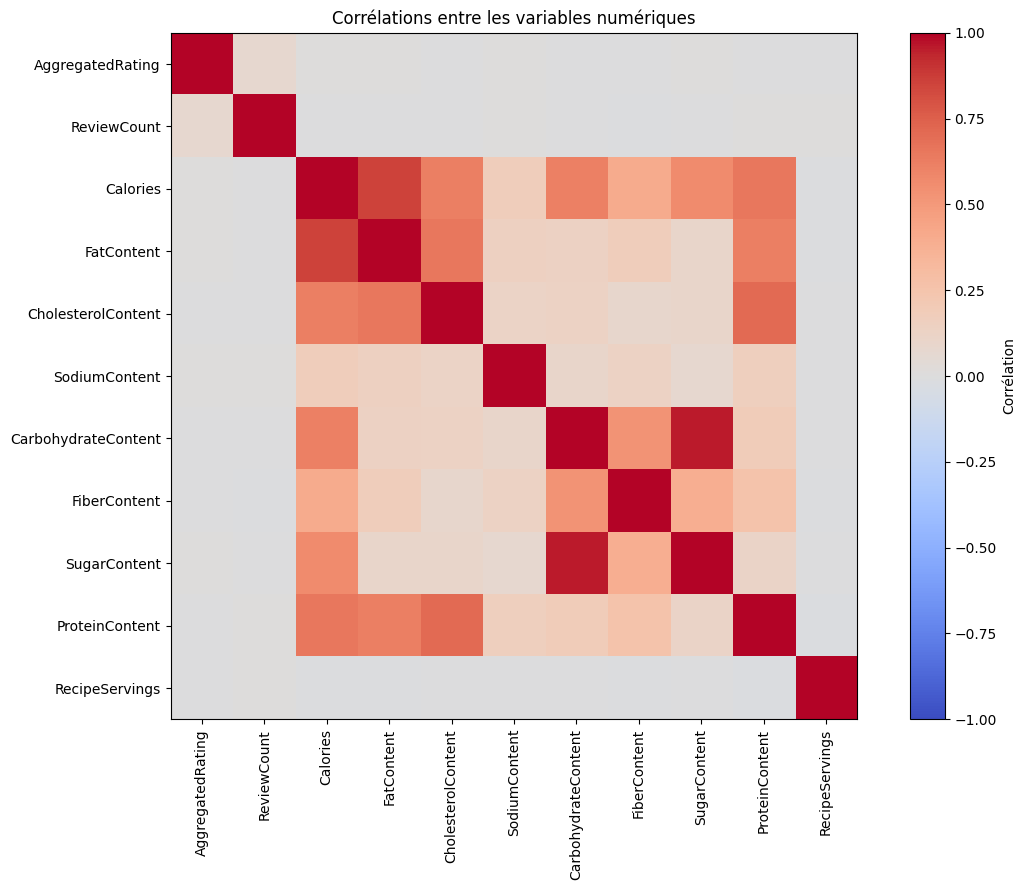

In [22]:
corr_columns = [
    "Calories",
    "FatContent",
    "ProteinContent",
    "CarbohydrateContent",
    "SugarContent",
    "FiberContent",
    "SodiumContent",
    "CholesterolContent",
    "TotalTime",
    "RecipeServings",
    "AggregatedRating",
    "ReviewCount"
]

corr_data = []

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=corr_columns,
    chunksize=50000
):
    corr_data.append(chunk)

corr_df = pd.concat(corr_data, ignore_index=True)

corr_matrix = corr_df.corr(numeric_only=True)

plt.figure(figsize=(12, 9))

plt.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar(label="Corrélation")

plt.xticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns,
    rotation=90
)

plt.yticks(
    range(len(corr_matrix.columns)),
    corr_matrix.columns
)

plt.title("Corrélations entre les variables numériques")

plt.tight_layout()
plt.show()

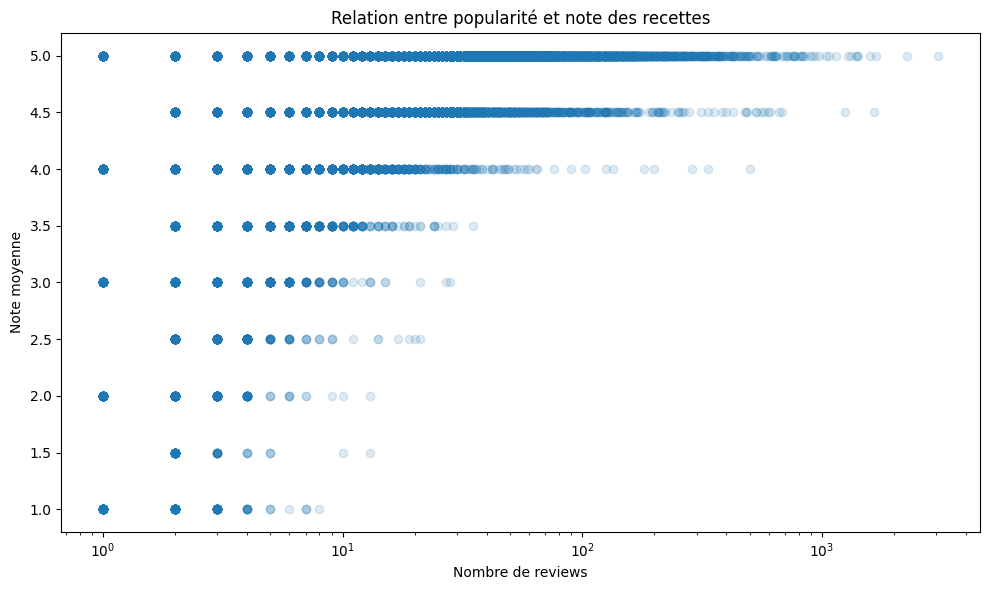

In [23]:
plt.figure(figsize=(10, 6))

plt.scatter(
    corr_df["ReviewCount"],
    corr_df["AggregatedRating"],
    alpha=0.15
)

plt.xlabel("Nombre de reviews")
plt.ylabel("Note moyenne")
plt.title("Relation entre popularité et note des recettes")
plt.xscale("log")

plt.tight_layout()
plt.show()